# Практика 3. Fine-tuning трансформера DistilBERT

**Задача:** определить, является ли SMS-сообщение спамом.

**Датасет:** [SMS Spam Collection (UCI)](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) — 5 574 реальных англоязычных SMS с разметкой `ham` (обычное) / `spam`. Данные «грязные»: есть повторяющиеся сообщения, HTML-сущности (`&lt;`, `&amp;`), сильный дисбаланс классов (~13 % спама).

**Модель:** [DistilBERT](https://arxiv.org/abs/1910.01108) — облегчённая версия BERT (архитектура **Transformer-encoder**), полученная методом дистилляции знаний: на 40 % меньше параметров (66 млн), на 60 % быстрее и сохраняет ~97 % качества BERT. Предобучена на Wikipedia и BookCorpus. Хороший выбор для дообучения на CPU.

**Что такое fine-tuning.** Предобученная модель уже «понимает» язык: умеет строить контекстные представления слов с помощью механизма **self-attention**. Мы добавляем сверху классификационную голову (Dense-слой) и **дообучаем всю модель** на нашей задаче с маленьким шагом обучения, чтобы не разрушить полученные при предобучении знания. Это позволяет получить сильную модель на небольшом датасете.

**План:** очистка и EDA текста → разбиение train/val/test → fine-tuning DistilBERT → подбор порога на валидации → честная оценка на тесте → анализ ошибок.

> ⚠️ Используется библиотека **KerasHub**. Её токенизаторы зависят от пакета `tensorflow-text`, у которого нет сборок под нативный Windows. На Windows запускайте тетрадь в **WSL2** или в Google Colab (подойдёт и бесплатный CPU-режим). На Linux/macOS всё ставится через pip.

## 0. Зависимости и импорты

In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn mlflow "tensorflow>=2.16" "keras-hub>=0.18"

In [2]:
import csv
import html
import os
import re
import zipfile
from collections import Counter
from pathlib import Path
from urllib.request import urlretrieve

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import keras
import keras_hub
from IPython.display import display
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

## 1. Настройки и вспомогательные функции

In [3]:
EXPERIMENT_NAME = "p3_distilbert_sms_spam"
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
LABELS = {"ham": 0, "spam": 1}
CLASS_NAMES = ["ham", "spam"]
PRESET = "distil_bert_base_en_uncased"
MAX_SEQUENCE_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
SAVE_MODEL = False
URL_PATTERN = re.compile(r"(?:https?://|www\.)\S+|\b\S+\.(?:com|net|org|co\.uk)\b", re.IGNORECASE)


SEED = 42
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
MLFLOW_URI = f"sqlite:///{(ROOT / 'mlflow.db').as_posix()}"

keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
print(f"Keras {keras.__version__}, backend: {keras.backend.backend()}")


def download(url, filename):
    path = DATA_DIR / filename
    if not path.exists():
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        urlretrieve(url, path)
    return path


def quality_report(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "missing_%": (frame.isna().mean() * 100).round(2),
        "unique": frame.nunique(),
    })


def iqr_outlier_mask(frame, k=1.5):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return (frame < q1 - k * iqr) | (frame > q3 + k * iqr)


class MlflowLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        mlflow.log_metrics({k: float(v) for k, v in (logs or {}).items()}, step=epoch)


def plot_history(history, metric):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, key in zip(axes, ["loss", metric]):
        ax.plot(history.history[key], label="train")
        ax.plot(history.history[f"val_{key}"], label="validation")
        ax.set(title=key, xlabel="эпоха")
        ax.legend()
    plt.tight_layout()
    return fig


def clean_text(text):
    text = html.unescape(text)
    return re.sub(r"\s+", " ", text).strip()


def classification_metrics(y_true, y_pred, y_score):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_score),
        "pr_auc": average_precision_score(y_true, y_score),
    }


def best_f1_threshold(y_true, y_score):
    precision, recall, thresholds = precision_recall_curve(y_true, y_score)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])


def softmax(logits):
    exp = np.exp(logits - logits.max(axis=1, keepdims=True))
    return exp / exp.sum(axis=1, keepdims=True)

2026/11/11 07:39:23 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/11 07:39:23 INFO mlflow.store.db.utils: Updating database tables
2026/11/11 07:39:31 INFO mlflow.tracking.fluent: Experiment with name 'p3_distilbert_sms_spam' does not exist. Creating a new experiment.


Keras 3.13.2, backend: tensorflow


**Трекинг экспериментов.** Метрики каждой эпохи пишутся в MLflow через callback `MlflowLogger` (база `mlflow.db` в корне репозитория). Просмотр: `mlflow ui --backend-store-uri sqlite:///mlflow.db` из корня репозитория → http://127.0.0.1:5000.

## 2. Загрузка данных
Файл — текст с табуляцией: `метка<TAB>сообщение`. Кавычки внутри SMS не являются экранированием, поэтому отключаем их обработку (`QUOTE_NONE`), иначе часть сообщений «склеится».

In [4]:
with zipfile.ZipFile(download(DATA_URL, "smsspamcollection.zip")) as archive:
    with archive.open("SMSSpamCollection") as f:
        raw = pd.read_csv(f, sep="\t", header=None, names=["label", "text"], quoting=csv.QUOTE_NONE,
                          encoding="utf-8", encoding_errors="replace", dtype=str)
df = raw.copy()
print(f"Сообщений: {len(df)}")
df.sample(5, random_state=SEED)

Сообщений: 5574


,label,text
3690,ham,You still coming tonight?
3527,ham,"""HEY BABE! FAR 2 SPUN-OUT 2 SPK AT DA MO... DE..."
724,ham,Ya even those cookies have jelly on them
3370,ham,Sorry i've not gone to that place. I.ll do so ...
468,ham,When are you going to ride your bike?


## 3. Качество данных
### 3.1. Пропуски, пустые сообщения, некорректные метки

In [5]:
df["label"] = df["label"].str.strip().str.lower()
empty_text = df["text"].isna() | df["text"].fillna("").str.strip().eq("")
bad_label = ~df["label"].isin(LABELS.keys())
print(f"Пропусков в label: {df['label'].isna().sum()}, в text: {df['text'].isna().sum()}")
print(f"Пустых сообщений: {empty_text.sum()}")
print(f"Некорректных меток: {bad_label.sum()} {df.loc[bad_label, 'label'].unique()[:5].tolist()}")
df = df.loc[~(empty_text | bad_label)].reset_index(drop=True)

Пропусков в label: 0, в text: 0
Пустых сообщений: 0
Некорректных меток: 0 []


**Стратегия:** сообщение без текста или с неизвестной меткой восстановить невозможно — удаляем. Заполнять пропуски в тексте бессмысленно.

### 3.2. «Битые» символы и нормализация
В исходных SMS встречаются HTML-сущности (`&lt;#&gt;` вместо `<#>`, `&amp;` вместо `&`) — артефакт выгрузки с веб-форума. Декодируем их и нормализуем пробелы. Регистр и пунктуацию **не трогаем**: токенизатор DistilBERT обрабатывает их сам, а КАПС и «!!!» — полезные признаки спама.

In [6]:
has_entities = df["text"].str.contains(r"&(?:lt|gt|amp|quot|#\d+);", regex=True)
has_replacement_char = df["text"].str.contains("\ufffd", regex=False)
print(f"Сообщений с HTML-сущностями: {has_entities.sum()}")
print(f"Сообщений с нераспознанными символами: {has_replacement_char.sum()}")
print("Пример до:", df.loc[has_entities, "text"].iloc[0] if has_entities.any() else "—")
df["text"] = df["text"].map(clean_text)
print("Пример после:", df.loc[has_entities, "text"].iloc[0] if has_entities.any() else "—")

Сообщений с HTML-сущностями: 309
Сообщений с нераспознанными символами: 0
Пример до: I'm back &amp; we're packing the car now, I'll let you know if there's room
Пример после: I'm back & we're packing the car now, I'll let you know if there's room


### 3.3. Дубликаты
Повторы в SMS-данных очень частые (шаблонные рассылки, «Ok», «Sorry, I'll call later»). Если одна копия попадёт в train, а другая в test, модель будет оцениваться на «выученных» примерах — это утечка. Сравниваем тексты **после** нормализации и без учёта регистра; отдельно проверяем противоречия (одинаковый текст с разными метками).

In [7]:
normalized = df["text"].str.lower()
conflict_texts = df.groupby(normalized)["label"].nunique().loc[lambda s: s > 1].index
conflicts = normalized.isin(conflict_texts)
duplicates = normalized.duplicated(keep="first")
print(f"Дубликатов: {duplicates.sum()} ({duplicates.mean():.1%})")
print(f"Сообщений с противоречивой разметкой: {conflicts.sum()}")
print("\nСамые частые повторы:")
print(normalized[normalized.duplicated(keep=False)].value_counts().head(8).to_string())
df = df.loc[~(duplicates | conflicts)].reset_index(drop=True)
df["target"] = df["label"].map(LABELS)
print(f"\nИтого сообщений: {len(df)}")

Дубликатов: 415 (7.4%)
Сообщений с противоречивой разметкой: 0

Самые частые повторы:
text
sorry, i'll call later                                                                                                                                                                 30
i cant pick the phone right now. pls send a message                                                                                                                                    12
ok...                                                                                                                                                                                  10
wen ur lovable bcums angry wid u, dnt take it seriously.. coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... have nice day da.     4
ok                                                                                                                                                                   

### 3.4. Аномалии длины
Строим признаки текста и ищем аномально длинные/короткие сообщения.

In [8]:
text_features = pd.DataFrame({
    "n_chars": df["text"].str.len(),
    "n_words": df["text"].str.split().str.len(),
    "n_digits": df["text"].str.count(r"\d"),
    "upper_ratio": df["text"].str.count(r"[A-Z]") / df["text"].str.len(),
    "n_exclam": df["text"].str.count("!"),
    "has_url": df["text"].str.contains(URL_PATTERN).astype(int),
    "has_currency": df["text"].str.contains(r"[£$€]|\bp(?:ence|/min)\b", regex=True).astype(int),
    "target": df["target"],
})
long_outliers = iqr_outlier_mask(text_features[["n_chars"]], k=3)["n_chars"]
print(f"Экстремально длинных сообщений (IQR, k=3): {long_outliers.sum()}")
print(f"Сообщений из 1 символа: {(text_features['n_chars'] == 1).sum()}")
df.loc[long_outliers, "text"].str.slice(0, 150).head(3).tolist()

Экстремально длинных сообщений (IQR, k=3): 19
Сообщений из 1 символа: 0


['You are everywhere dirt, on the floor, the windows, even on my shirt. And sometimes when i open my mouth, you are all that comes flowing out. I dream ',
 'Sir, I have been late in paying rent for the past few months and had to pay a $ <#> charge. I felt it would be inconsiderate of me to nag about someth',
 'For me the love should start with attraction.i should feel that I need her every time around me.she should be the first thing which comes in my though']

Длинные сообщения — это реальные письма и пересказы, а не мусор; DistilBERT всё равно обрежет их до максимальной длины последовательности. Поэтому выбросы оставляем, а длину последовательности выбираем по распределению длин в токенах (ниже).

## 4. Разведочный анализ (EDA)

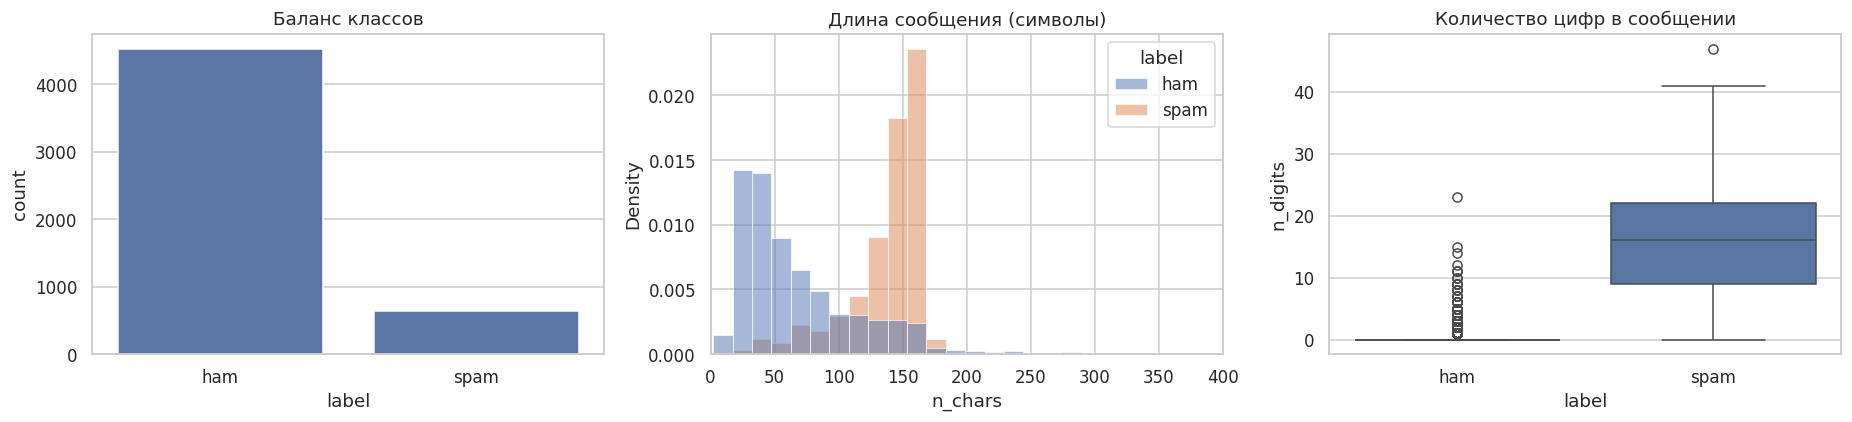

label
ham     0.876
spam    0.124


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.countplot(x=df["label"], ax=axes[0])
axes[0].set_title("Баланс классов")
sns.histplot(data=text_features.assign(label=df["label"]), x="n_chars", hue="label", bins=60, ax=axes[1], stat="density", common_norm=False)
axes[1].set(title="Длина сообщения (символы)", xlim=(0, 400))
sns.boxplot(data=text_features.assign(label=df["label"]), x="label", y="n_digits", ax=axes[2])
axes[2].set_title("Количество цифр в сообщении")
plt.tight_layout()
plt.show()
print(df["label"].value_counts(normalize=True).round(3).to_string())

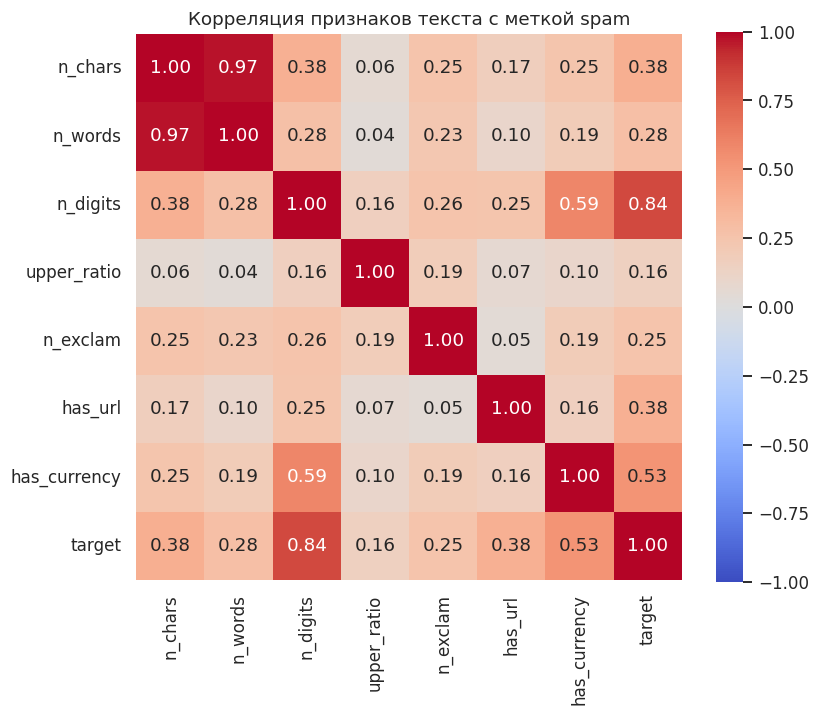

In [10]:
plt.figure(figsize=(8, 6.5))
sns.heatmap(text_features.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Корреляция признаков текста с меткой spam")
plt.show()

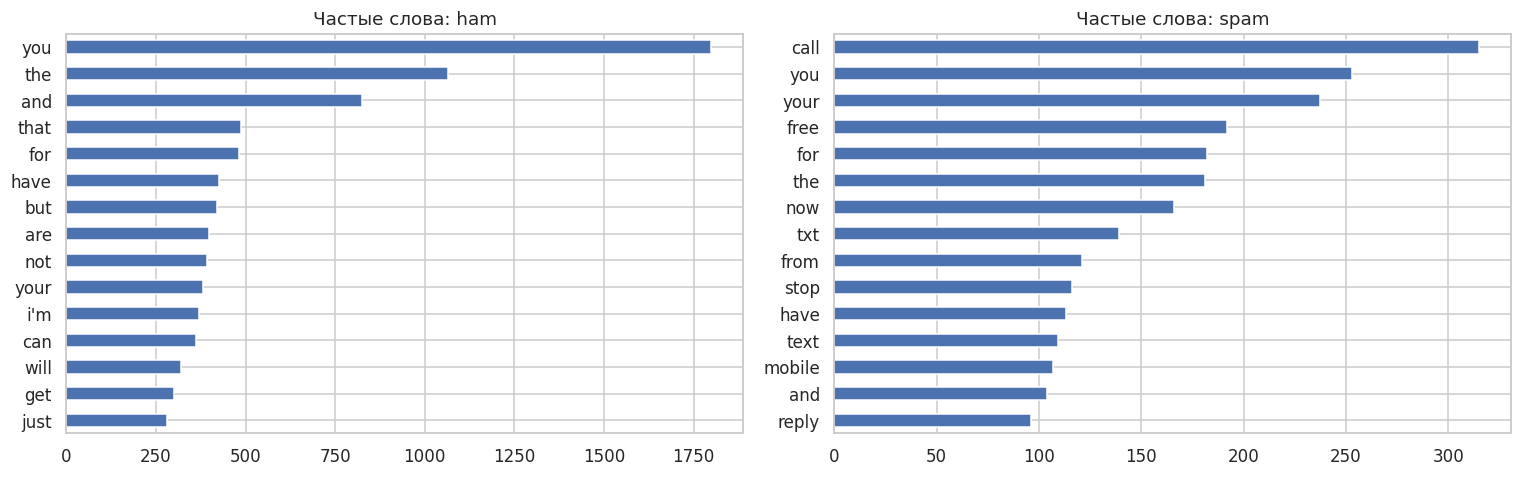

In [11]:
def top_words(texts, n=15):
    words = Counter(w for t in texts for w in re.findall(r"[a-z']{3,}", t.lower()))
    return pd.Series(dict(words.most_common(n)))


fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, label in zip(axes, CLASS_NAMES):
    top_words(df.loc[df["label"] == label, "text"]).sort_values().plot.barh(ax=ax)
    ax.set_title(f"Частые слова: {label}")
plt.tight_layout()
plt.show()

**Наблюдения EDA:** спам длиннее и содержит больше цифр (телефоны, короткие номера, суммы): у числа цифр самая сильная корреляция с меткой — **0,84**, далее знаки валют (0,53), длина и ссылки (0,38). Частые слова в спаме — *call, free, now, txt, stop, text, mobile, reply*: призывы позвонить или ответить на короткий номер. Дисбаланс классов ≈ 7 : 1 (12,4 % спама), поэтому основные метрики — **F1, precision, recall и PR-AUC** для класса spam, а не accuracy: модель, которая всегда отвечает «ham», уже даст accuracy ≈ 0,88.

## 5. Разбиение выборки
Стратифицированное разбиение **70 / 15 / 15**. Валидация используется для ранней остановки и выбора порога классификации, тест — один раз в конце.

In [12]:
X_train, X_tmp, y_train, y_tmp = train_test_split(
    df["text"].to_numpy(dtype=str), df["target"].to_numpy(), test_size=0.3, stratify=df["target"], random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=SEED)
for name, labels in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:>5}: {len(labels)} сообщений, доля спама {labels.mean():.3f}")

train: 3611 сообщений, доля спама 0.124
  val: 774 сообщений, доля спама 0.125
 test: 774 сообщений, доля спама 0.124


## 6. Подготовка DistilBERT
### 6.1. Токенизация и длина последовательности
DistilBERT работает не со словами, а с **WordPiece-токенами** (подсловами): редкое слово разбивается на части, например `claiming` → `claim`, `##ing`. В начало добавляется служебный токен `[CLS]`, по представлению которого делается классификация, в конец — `[SEP]`.

Длина входа фиксирована: длинные тексты обрезаются, короткие дополняются `[PAD]`. Вычислительная сложность self-attention растёт квадратично с длиной, поэтому выбираем минимальную длину, покрывающую ~99 % сообщений.

['winner', '!', '!', 'you', 'have', 'been', 'selected', 'to', 'receive', 'a', '£', '##90', '##0', 'prize', 'reward', '!', 'call', '09', '##0', '##6', '##17', '##01', '##46', '##1']
Длина в токенах: медиана 19, 99-й перцентиль 68, максимум 221
Выбранная длина последовательности: 80; обрезается 0.61% сообщений


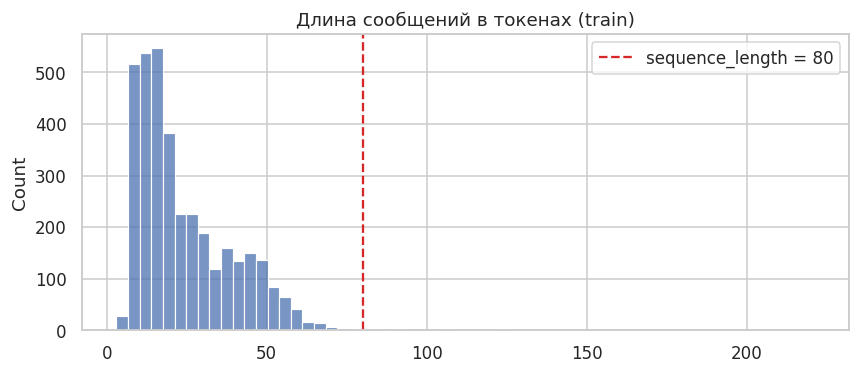

In [13]:
tokenizer = keras_hub.models.DistilBertTokenizer.from_preset(PRESET)
sample_text = "WINNER!! You have been selected to receive a £900 prize reward! Call 09061701461"
sample_ids = np.asarray(tokenizer(sample_text))
print([tokenizer.id_to_token(int(i)) for i in sample_ids])

token_lengths = np.array([len(np.asarray(tokenizer(text))) + 2 for text in X_train])
p99 = int(np.percentile(token_lengths, 99))
SEQUENCE_LENGTH = int(min(MAX_SEQUENCE_LENGTH, 16 * np.ceil(p99 / 16)))
print(f"Длина в токенах: медиана {np.median(token_lengths):.0f}, 99-й перцентиль {p99}, максимум {token_lengths.max()}")
print(f"Выбранная длина последовательности: {SEQUENCE_LENGTH}; обрезается {(token_lengths > SEQUENCE_LENGTH).mean():.2%} сообщений")

plt.figure(figsize=(9, 3.5))
sns.histplot(token_lengths, bins=60)
plt.axvline(SEQUENCE_LENGTH, color="tab:red", linestyle="--", label=f"sequence_length = {SEQUENCE_LENGTH}")
plt.title("Длина сообщений в токенах (train)")
plt.legend()
plt.show()

### 6.2. Модель
`DistilBertTextClassifier` из KerasHub = **препроцессор** (токенизация + паддинг + маска внимания) → **backbone** DistilBERT (6 слоёв трансформера, 12 голов внимания, скрытый размер 768) → **классификационная голова** (Dense над представлением `[CLS]`, dropout).

Веса backbone загружаются предобученными, голова инициализируется случайно. При fine-tuning обновляются **все** веса.

Настройки дообучения:
- **AdamW**, шаг обучения 3·10⁻⁵ — стандарт для BERT-подобных моделей; большой шаг «сотрёт» предобученные знания (catastrophic forgetting);
- 3 эпохи с ранней остановкой по `val_loss` — трансформеры быстро переобучаются на маленьких данных;
- **веса классов** компенсируют дисбаланс: ошибка на редком спаме штрафуется сильнее.

In [14]:
preprocessor = keras_hub.models.DistilBertTextClassifierPreprocessor.from_preset(PRESET, sequence_length=SEQUENCE_LENGTH)
classifier = keras_hub.models.DistilBertTextClassifier.from_preset(PRESET, num_classes=2, preprocessor=preprocessor)
classifier.compile(
    optimizer=keras.optimizers.AdamW(learning_rate=LEARNING_RATE, weight_decay=WEIGHT_DECAY),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)
classifier.summary()

class_weight = dict(enumerate(compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)))
print("Веса классов:", {CLASS_NAMES[k]: round(v, 3) for k, v in class_weight.items()})

Preprocessor: "distil_bert_text_classifier_preprocessor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ distil_bert_tokenizer (DistilBertTokenizer)                   │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "distil_bert_text_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │      66,362,880 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           1,538 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 66,955,010 (255.41 MB)

 Trainable params: 66,955,010 (255.41 MB)

 Non-trainable params: 0 (0.00 B)

Веса классов: {'ham': np.float64(0.571), 'spam': np.float64(4.021)}


## 7. Fine-tuning
Обучение на CPU занимает около часа на эпоху, на GPU — 1–2 минуты. Для быстрой проверки можно временно поставить `PRESET = "bert_tiny_en_uncased"` (4 млн параметров, класс `BertTextClassifier`).

Epoch 1/3
226/226 ━━━━━━━━━━━━━━━━━━━━ 3349s 15s/step - accuracy: 0.9693 - loss: 0.1561 - val_accuracy: 0.9729 - val_loss: 0.0882
Epoch 2/3
226/226 ━━━━━━━━━━━━━━━━━━━━ 3329s 14s/step - accuracy: 0.9886 - loss: 0.0503 - val_accuracy: 0.9832 - val_loss: 0.0763
Epoch 3/3
226/226 ━━━━━━━━━━━━━━━━━━━━ 3370s 15s/step - accuracy: 0.9967 - loss: 0.0226 - val_accuracy: 0.8941 - val_loss: 0.4472


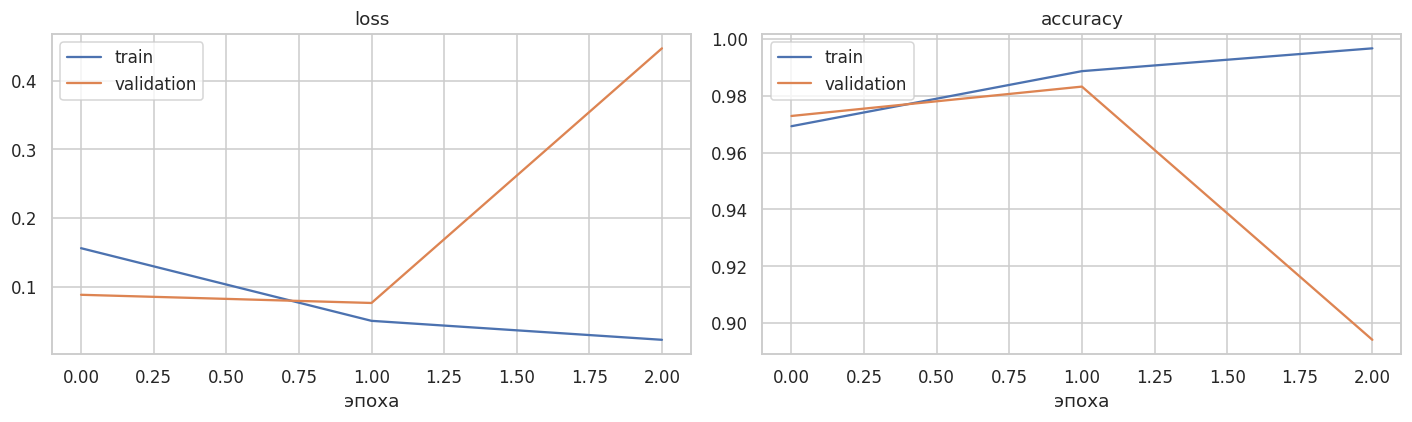

In [15]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True),
    MlflowLogger(),
]
with mlflow.start_run(run_name="distilbert_finetune") as run:
    mlflow.log_params({
        "preset": PRESET, "sequence_length": SEQUENCE_LENGTH, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
        "lr": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "class_weight": class_weight,
        "n_params": classifier.count_params(), "n_train": len(X_train),
    })
    history = classifier.fit(
        x=X_train, y=y_train, validation_data=(X_val, y_val), epochs=EPOCHS,
        batch_size=BATCH_SIZE, class_weight=class_weight, callbacks=callbacks,
    )
run_id = run.info.run_id
history_fig = plot_history(history, "accuracy")
plt.show()

## 8. Выбор порога на валидации
Модель выдаёт вероятность спама. Порог 0.5 не обязательно оптимален при дисбалансе классов. Подбираем порог, максимизирующий F1 на **валидации**, и затем без изменений применяем его к тесту.

In [16]:
val_score = softmax(classifier.predict(X_val, batch_size=64, verbose=0))[:, 1]
threshold = best_f1_threshold(y_val, val_score)
val_metrics = classification_metrics(y_val, (val_score >= threshold).astype(int), val_score)
print(f"Порог по F1 на валидации: {threshold:.3f}")
pd.Series(val_metrics).round(4)

Порог по F1 на валидации: 0.432


,0
accuracy,0.9845
precision,0.9670
recall,0.9072
f1,0.9362
roc_auc,0.9950
pr_auc,0.9757


## 9. Финальная оценка на тестовой выборке

In [17]:
test_score = softmax(classifier.predict(X_test, batch_size=64, verbose=0))[:, 1]
test_pred = (test_score >= threshold).astype(int)
test_metrics = classification_metrics(y_test, test_pred, test_score)
print(classification_report(y_test, test_pred, target_names=CLASS_NAMES, digits=4))
pd.Series(test_metrics).round(4)

              precision    recall  f1-score   support

         ham     0.9898    1.0000    0.9949       678
        spam     1.0000    0.9271    0.9622        96

    accuracy                         0.9910       774
   macro avg     0.9949    0.9635    0.9785       774
weighted avg     0.9910    0.9910    0.9908       774



,0
accuracy,0.9910
precision,1.0000
recall,0.9271
f1,0.9622
roc_auc,0.9965
pr_auc,0.9872


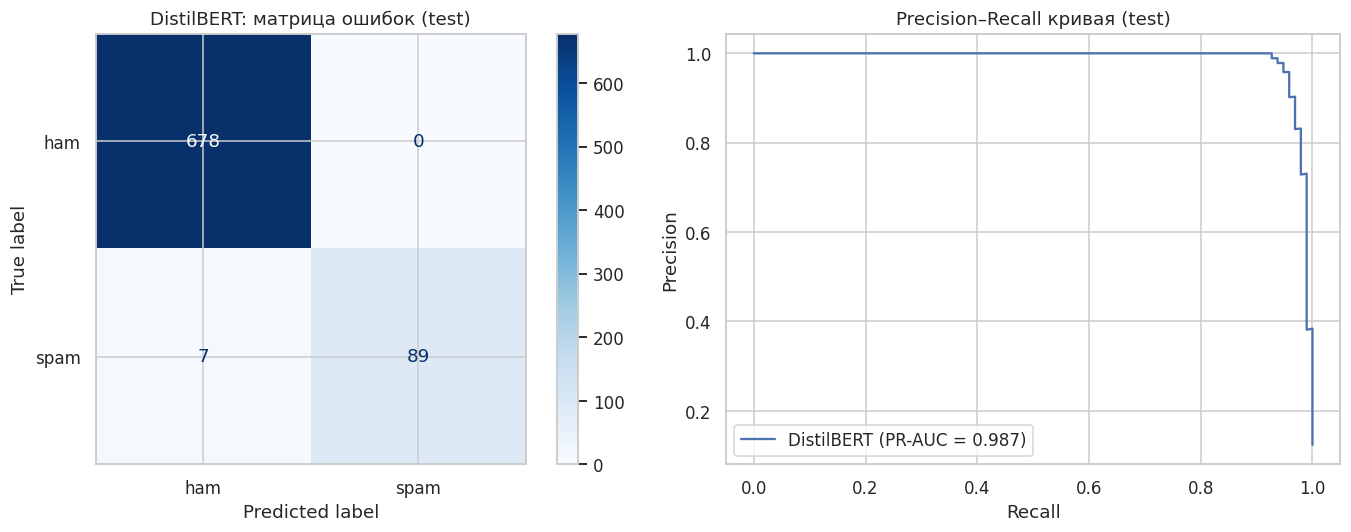

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=CLASS_NAMES, cmap="Blues", ax=axes[0])
axes[0].set_title("DistilBERT: матрица ошибок (test)")
precision, recall, _ = precision_recall_curve(y_test, test_score)
axes[1].plot(recall, precision, label=f"DistilBERT (PR-AUC = {test_metrics['pr_auc']:.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall кривая (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Анализ ошибок
Смотрим, на каких сообщениях модель ошибается: ложные срабатывания (обычное SMS принято за спам) особенно неприятны пользователю.

In [19]:
errors = pd.DataFrame({"text": X_test, "true": np.array(CLASS_NAMES)[y_test],
                       "spam_probability": test_score.round(3)})
errors = errors[test_pred != y_test].sort_values("spam_probability", ascending=False)
with pd.option_context("display.max_colwidth", 160):
    display(errors)

,text,true,spam_probability
717,Adult 18 Content Your video will be with you shortly,spam,0.309
710,3. You have received your mobile content. Enjoy,spam,0.201
673,Guess who am I?This is the first time I created a web page WWW.ASJESUS.COM read all I wrote. I'm waiting for your opinions. I want to be your friend 1/1,spam,0.050
213,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!",spam,0.020
671,Your weekly Cool-Mob tones are ready to download !This weeks new Tones include: 1) Crazy Frog-AXEL F>>> 2) Akon-Lonely>>> 3) Black Eyed-Dont P >>>More info ...,spam,0.012
163,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the next link sent to ur fone...,spam,0.006
205,FreeMsg>FAV XMAS TONES!Reply REAL,spam,0.004


In [20]:
new_messages = np.array([
    "Congratulations! You've won a free iPhone. Reply YES to claim your prize now!",
    "Hey, are we still meeting for lunch tomorrow at 1?",
    "URGENT: your account has been suspended, verify at www.secure-login-bank.com",
    "Can you pick up some milk on your way home? Thanks!",
])
new_scores = softmax(classifier.predict(new_messages, verbose=0))[:, 1]
pd.DataFrame({"сообщение": new_messages, "P(spam)": new_scores.round(3),
              "прогноз": np.where(new_scores >= threshold, "spam", "ham")})

,сообщение,P(spam),прогноз
0,Congratulations! You've won a free iPhone. Rep...,0.044,ham
1,"Hey, are we still meeting for lunch tomorrow a...",0.003,ham
2,"URGENT: your account has been suspended, verif...",0.642,spam
3,Can you pick up some milk on your way home? Th...,0.004,ham


In [21]:
with mlflow.start_run(run_id=run_id):
    mlflow.log_param("threshold", threshold)
    mlflow.log_metrics({f"final_val_{k}": v for k, v in val_metrics.items()})
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
    mlflow.log_figure(fig, "confusion_matrix_pr_curve.png")
    mlflow.log_figure(history_fig, "learning_curves.png")

if SAVE_MODEL:
    model_path = ROOT / "models" / "distilbert_sms_spam.keras"
    model_path.parent.mkdir(exist_ok=True)
    classifier.save(model_path)
    print(f"Модель сохранена: {model_path}")
print("Результаты записаны в MLflow")

Результаты записаны в MLflow


## 10. Выводы
- **Качество данных.** Пропусков, пустых сообщений и некорректных меток в 5 574 SMS нет. Декодированы HTML-сущности в 309 сообщениях (`&amp;` → `&` и т. п.). Удалено **415 дубликатов (7,4 %)** — например, «Sorry, I'll call later» встречалось 30 раз; противоречивой разметки нет. 19 экстремально длинных сообщений оставлены как реальные. Итог — 5 159 сообщений, 12,4 % спама.
- **Токенизация.** Медианная длина — 19 токенов, 99-й перцентиль — 68, поэтому выбрана длина последовательности **80**: обрезается лишь 0,61 % сообщений. WordPiece разбивает редкие слова и номера на подслова (`£900` → `£`, `##90`, `##0`).
- **Fine-tuning.** После 1-й эпохи `val_loss` = 0,088, после 2-й — **0,076** (лучшая). На 3-й эпохе модель **переобучилась**: loss на train упал до 0,023, а на валидации вырос до 0,447 (точность упала до 0,894). Ранняя остановка вернула веса 2-й эпохи. Это показывает, почему для трансформеров нужны малый шаг обучения, 2–4 эпохи и контроль по валидации.
- **Порог.** На валидации оптимальный по F1 порог — 0,432 (F1 0,936, ROC-AUC 0,995).
- **Итог на тесте (774 сообщения, 96 спам):** accuracy **0,991**, precision **1,000**, recall **0,927**, F1 **0,962**, ROC-AUC **0,997**, PR-AUC **0,987**. Модель **ни разу не пометила обычное сообщение как спам** и пропустила 7 спам-сообщений из 96.
- **Анализ ошибок.** Пропущенный спам — короткие «сервисные» сообщения без типичных спам-слов («Your video will be with you shortly», «You have received your mobile content») и рекламные рассылки мелодий. По содержанию они похожи на обычные уведомления.
- **Ограничение.** На новых сообщениях модель распознала фишинг про блокировку аккаунта (P(spam) = 0,64), но **пропустила** «Congratulations! You've won a free iPhone…» (P(spam) = 0,04). Датасет собран в Великобритании в 2000-х: спам в нём — это «txt», «call 0906…», «£», и модель выучила именно эти паттерны. Современный спам отличается от обучающих данных, и для реального применения модель нужно дообучать на свежих примерах.